# Notebook 09 — Training Hyperparameter Search

**Hyperparameter-optimisation experiment · Soccer Event Transformer · Track A model family**

| Item | Content |
|---|---|
| **Question** | For the architectures with the lowest validation NLL in the capacity sweep, do different training hyperparameters lower validation NLL further than the Track A setting (learning rate 3e-4, weight decay 0.1, batch 256, warm-up 5%)? |
| **Purpose of this notebook** | Search learning rate, weight decay, warm-up fraction and batch size on the two best shortlisted architectures, refine around the best setting with two seeds, and fix one training setting with which every shortlisted architecture is then benchmarked across five seeds. |
| **Inputs** | `results/08_capacity_runs.csv` (one row per capacity-sweep run, all at the Track A training setting, seeds 0 and 1) and `results/08_top_configs.json` (the shortlist: the five architectures with the lowest mean validation NLL in the sweep, plus the Track A architecture). |
| **What is varied** | Learning rate, weight decay, warm-up fraction, batch size. |
| **What is held fixed** | Dataset, preprocessing, splits, evaluation protocol, epoch budget (30), early-stopping patience (5), gradient clipping (1.0), learning-rate schedule shape (warm-up then cosine to 10% of peak), and the architectures themselves. |
| **Test data** | Not used. The test split stays locked. |
| **Outputs** | `results/09_hyperparameter_runs.csv`, `results/09_stage2_summary.csv`, `results/09_stage3_summary.csv`, `results/09_selected_training.json`, `results/09_candidates.json`, `results/09_summary.json`, figures in `figures/`. |


In [ ]:
  # ---------------------------------------------------------------------------
# Environment setup (identical at the top of every notebook of this experiment)
# ---------------------------------------------------------------------------
import os
import sys
import json
import time
import math
import copy
import hashlib
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")


PROJECT_DIR = Path(os.environ.get("TRACK_A_DIR", "/content/drive/MyDrive/soccer_mi/track_a"))
RUN_MODE = os.environ.get("TRACK_A_RUN_MODE", "full")
assert RUN_MODE in ("full", "smoke")
os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

# Existing Track A outputs.
EXISTING_DIR = PROJECT_DIR if RUN_MODE == "full" else PROJECT_DIR / "smoke"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
EXISTING_RUNS_DIR = EXISTING_DIR / "runs"
EXISTING_RESULTS_DIR = EXISTING_DIR / "results"
EXISTING_FROZEN_CONFIG = EXISTING_DIR / "config" / "frozen_config.json"

OPT_DIR = EXISTING_DIR / "experiments" / "hyperparameter_optimisation"
RUNS_DIR = OPT_DIR / "runs"
RESULTS_DIR = OPT_DIR / "results"
FIGURES_DIR = OPT_DIR / "figures"
CONFIG_DIR = OPT_DIR / "config"
MANIFEST_DIR = OPT_DIR / "manifests"
LOG_DIR = OPT_DIR / "logs"
for folder in [RUNS_DIR, RESULTS_DIR, FIGURES_DIR, CONFIG_DIR, MANIFEST_DIR, LOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
MANIFEST_PATH = MANIFEST_DIR / "experiment_manifest.jsonl"


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("Track A project (read-only):", EXISTING_DIR)
print("Experiment outputs:", OPT_DIR)

Mounted at /content/drive
Colab: True | RUN_MODE: full
Track A project (read-only): /content/drive/MyDrive/soccer_mi/track_a
Experiment outputs: /content/drive/MyDrive/soccer_mi/track_a/experiments/hyperparameter_optimisation


In [ ]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import importlib

import src.data as data
import src.batching as batching
import src.metrics as metrics
import src.model as model_module
import src.mlp_baseline as mlp_baseline
import src.training as training
import src.analysis as analysis
for module in [data, batching, metrics, model_module, mlp_baseline, training, analysis]:
    importlib.reload(module)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 240)
pd.set_option("display.max_columns", 60)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if RUN_MODE == "full" and DEVICE != "cuda":
    raise RuntimeError("BLOCKED: full-mode training requires a GPU. In Colab: Runtime > Change runtime type > GPU.")

events = pd.read_parquet(ARTIFACTS_DIR / "events_prepared.parquet")
targets = events["action_id"].to_numpy().astype("int64")
match_ids = events["match_id"].to_numpy()

with open(EXISTING_FROZEN_CONFIG) as handle:
    TRACK_A_FROZEN = json.load(handle)

# Fixed by Track A
ENCODING = TRACK_A_FROZEN["encoding"]
POSSESSION_FEATURES = TRACK_A_FROZEN["possession_features"]
STRIDE = TRACK_A_FROZEN["stride"]

BASE_LAYERS = TRACK_A_FROZEN["model"]["n_layers"]
BASE_HEADS = TRACK_A_FROZEN["model"]["n_heads"]
BASE_D_MODEL = TRACK_A_FROZEN["model"]["d_model"]
BASE_D_FF = TRACK_A_FROZEN["model"]["d_ff"]
BASE_CONTEXT = TRACK_A_FROZEN["context_length"]
BASE_LR = TRACK_A_FROZEN["training"]["learning_rate"]
BASE_WD = TRACK_A_FROZEN["training"]["weight_decay"]
EPOCH_BUDGET = TRACK_A_FROZEN["training"]["max_epochs"]

print("Events:", len(events), "| device:", DEVICE)
print("Track A reference configuration:",
      f"L{BASE_LAYERS} H{BASE_HEADS} d_model {BASE_D_MODEL} d_ff {BASE_D_FF} K{BASE_CONTEXT}",
      f"| lr {BASE_LR:g} wd {BASE_WD:g} | epoch budget {EPOCH_BUDGET}")

Events: 658905 | device: cuda
Track A reference configuration: L2 H2 d_model 128 d_ff 512 K16 | lr 0.0003 wd 0.1 | epoch budget 30


In [ ]:
# ----------------
# Helper functions
# ----------------

SHORT_NAME = {"batch_size": "bs", "warmup_fraction": "wu"}


def transformer_config(seed, n_layers, n_heads, context_length, d_model=None, d_ff=None,
                       learning_rate=None, weight_decay=None, max_epochs=None):
    """Build a run configuration in exactly the format used by the Track A notebooks."""
    model = {"n_layers": n_layers, "n_heads": n_heads,
             "d_model": BASE_D_MODEL if d_model is None else d_model,
             "d_ff": BASE_D_FF if d_ff is None else d_ff}
    training_settings = {"learning_rate": BASE_LR if learning_rate is None else learning_rate,
                         "weight_decay": BASE_WD if weight_decay is None else weight_decay,
                         "max_epochs": EPOCH_BUDGET if max_epochs is None else max_epochs}
    return {"model_type": "transformer", "encoding": ENCODING, "possession_features": POSSESSION_FEATURES,
            "context_length": context_length, "stride": STRIDE, "seed": seed,
            "model": model, "training": training_settings}


def architecture_label(config):
    """Readable architecture name, e.g. L4-H2-K16-D128-F512."""
    model = config["model"]
    return (f"L{model['n_layers']}-H{model['n_heads']}-K{config['context_length']}"
            f"-D{model['d_model']}-F{model['d_ff']}")


def variant_tag(training_settings):
    """Sub-folder for training settings that training.run_name_for() does not encode.

    run_name_for() encodes the learning rate, weight decay, architecture, context length and
    seed, but not the batch size or the warm-up fraction. To prevent runs that differ only in those
    two settings (batch size or the warm-up fraction) to be written to the same folder.
    """
    parts = []
    for key in ["batch_size", "warmup_fraction"]:
        if key in training_settings and training_settings[key] != training.DEFAULT_TRAINING[key]:
            parts.append(f"{SHORT_NAME[key]}{training_settings[key]:g}")
    return "_".join(parts) if parts else "base"


_BUNDLES = {}


def bundle_for(context_length):
    """Encoded data and evaluation views for one context length."""
    if context_length not in _BUNDLES:
        _BUNDLES[context_length] = training.prepare_data(
            events, ARTIFACTS_DIR, ENCODING, POSSESSION_FEATURES, context_length, STRIDE, DEVICE, RUN_MODE)
    return _BUNDLES[context_length]


def parameter_count(config):
    """Total parameters of a configuration, without training."""
    model = training.build_model(config, bundle_for(config["context_length"])["vocabulary_sizes"])
    return model_module.count_parameters(model)["total"]


def run_one(config, extra_training=None, keep_every_epoch=False, verbose=True):
    """Train one configuration (or reload it if its folder already holds a finished run).

    Returns (run_dir, final_results). Nothing outside RUNS_DIR is written.
    """
    config = copy.deepcopy(config)
    if extra_training:
        config["training"].update(extra_training)
    runs_root = RUNS_DIR / variant_tag(config["training"])
    runs_root.mkdir(parents=True, exist_ok=True)
    result = training.train_run(config, bundle_for(config["context_length"]), runs_root,
                                MANIFEST_PATH, keep_every_epoch=keep_every_epoch, verbose=verbose)
    return runs_root / training.run_name_for(config), result


def result_row(config, run_dir, result, group=""):
    """One flat record per run, required in later notebooks."""
    val = result["val_metrics"]
    training_settings = result["training_settings"]
    return {
        "group": group,
        "architecture": architecture_label(config),
        "n_layers": config["model"]["n_layers"],
        "n_heads": config["model"]["n_heads"],
        "d_head": config["model"]["d_model"] // config["model"]["n_heads"],
        "d_model": config["model"]["d_model"],
        "d_ff": config["model"]["d_ff"],
        "context_length": config["context_length"],
        "learning_rate": training_settings["learning_rate"],
        "weight_decay": training_settings["weight_decay"],
        "batch_size": training_settings["batch_size"],
        "warmup_fraction": training_settings["warmup_fraction"],
        "seed": config["seed"],
        "parameters": result["parameter_counts"]["total"],
        "trainable_parameters": result["parameter_counts"].get("trainable", result["parameter_counts"]["total"]),
        "val_nll": val["nll"],
        "val_accuracy": val["accuracy"],
        "val_macro_f1": val["macro_f1"],
        "val_top3": val["top3_accuracy"],
        "val_top5": val["top5_accuracy"],
        "val_ece": val["ece"],
        "train_nll": result["train_nll"],
        "best_epoch": result["best_epoch"],
        "epochs_run": result["epochs_run"],
        "stopped_early": result["stopped_early"],
        "diverged": result["diverged"],
        "runtime_seconds": result["runtime_seconds"],
        "run_dir": str(run_dir),
        "run_name": result["run_name"],
    }


def append_results(rows, csv_path):
    """Append run records to a CSV, keeping one row per run name and variant folder."""
    table = pd.DataFrame(rows)
    if Path(csv_path).exists():
        table = pd.concat([pd.read_csv(csv_path), table], ignore_index=True)
    table = table.drop_duplicates(subset=["run_dir"], keep="last").reset_index(drop=True)
    table.to_csv(csv_path, index=False)
    return table


def seed_level_to_config_level(table):
    """Average the seed-level records of each configuration into one row per configuration."""
    keys = ["group", "architecture", "n_layers", "n_heads", "d_head", "d_model", "d_ff",
            "context_length", "learning_rate", "weight_decay", "batch_size", "warmup_fraction",
            "parameters"]
    summary = table.groupby(keys, as_index=False, sort=False).agg(
        n_seeds=("seed", "count"),
        val_nll=("val_nll", "mean"),
        val_nll_sd=("val_nll", "std"),
        val_accuracy=("val_accuracy", "mean"),
        val_accuracy_sd=("val_accuracy", "std"),
        val_macro_f1=("val_macro_f1", "mean"),
        val_top3=("val_top3", "mean"),
        val_top5=("val_top5", "mean"),
        val_ece=("val_ece", "mean"),
        train_nll=("train_nll", "mean"),
        best_epoch=("best_epoch", "mean"),
        runtime_seconds=("runtime_seconds", "mean"),
    )
    return summary.sort_values("val_nll").reset_index(drop=True)


def run_dirs_for(table, **conditions):
    """All run directories in a results table that match the given column values."""
    selected = table
    for column, value in conditions.items():
        selected = selected[selected[column] == value]
    return [Path(path) for path in selected["run_dir"]]


print("Helper functions defined.")

Helper functions defined.


## 1. Input: the capacity-sweep shortlist

The shortlist holds six architectures, all at K = 16, d_model 128 and d_ff 512: L6-H2 (screening validation NLL 0.9020), L8-H2 (0.9024), L6-H1 (0.9026), L4-H2 (0.9027), L6-H8 (0.9030), and the Track A architecture L2-H2 (0.9064). Each value is the mean over seeds 0 and 1 at the Track A training setting.

In [ ]:
CAPACITY_RUNS_CSV = RESULTS_DIR / "08_capacity_runs.csv"
TOP_CONFIGS_JSON = RESULTS_DIR / "08_top_configs.json"
for required in [CAPACITY_RUNS_CSV, TOP_CONFIGS_JSON]:
    if not required.exists():
        raise RuntimeError(f"BLOCKED: {required.name} is missing. Run notebook 08 first.")

capacity_table = pd.read_csv(CAPACITY_RUNS_CSV)
with open(TOP_CONFIGS_JSON) as handle:
    shortlist_record = json.load(handle)
SHORTLIST = shortlist_record["configurations"]

HYPERPARAMETER_RUNS_CSV = RESULTS_DIR / "09_hyperparameter_runs.csv"
STAGE2_SUMMARY_CSV = RESULTS_DIR / "09_stage2_summary.csv"
STAGE3_SUMMARY_CSV = RESULTS_DIR / "09_stage3_summary.csv"
CANDIDATES_JSON = RESULTS_DIR / "09_candidates.json"

print("Shortlist from notebook 08:")
pd.DataFrame(SHORTLIST)[["architecture", "n_layers", "n_heads", "context_length", "d_model", "d_ff",
                         "parameters", "screening_val_nll", "is_track_a_reference"]].round(4)

Shortlist from notebook 08:


,architecture,n_layers,n_heads,context_length,d_model,d_ff,parameters,screening_val_nll,is_track_a_reference
0,L6-H2-K16-D128-F512,6,2,16,128,512,1307663,0.9020,False
1,L8-H2-K16-D128-F512,8,2,16,128,512,1704207,0.9024,False
2,L6-H1-K16-D128-F512,6,1,16,128,512,1307663,0.9026,False
3,L4-H2-K16-D128-F512,4,2,16,128,512,911119,0.9027,False
4,L6-H8-K16-D128-F512,6,8,16,128,512,1307663,0.9030,False
5,L2-H2-K16-D128-F512,2,2,16,128,512,514575,0.9064,True


## 2. Design of the search

Searching four hyperparameters on every shortlisted architecture would multiply the run count by the size of the shortlist. The search is narrowed in two stages.

**Stage 2 — coarse grid.** The two non-reference architectures with the lowest screening NLL (L6-H2-K16 and L8-H2-K16) receive a full grid over learning rate ∈ {1e-4, 3e-4, 1e-3} and weight decay ∈ {0.01, 0.1, 0.3}, one seed (seed 0) per cell. Warm-up fraction ∈ {0.02, 0.05, 0.10} and batch size ∈ {128, 256, 512} are then varied one at a time around the best cell of each architecture: a four-way grid is not affordable, and warm-up and batch size interact mainly with the learning rate, which the grid has already located. The number of searched architectures (two) is a compute budget.

**Stage 3 — fine search.** The single best (architecture, learning rate, weight decay) combination from stage 2 is refined: learning rates at the geometric midpoints between the coarse grid points on either side of the selected value, and the selected weight decay with its grid neighbours. Two seeds (0 and 1) per cell.

**Why geometric values.** The effect of the learning rate is roughly multiplicative, so a linear grid would spend most of its points in a narrow region. The weight-decay values likewise span a factor of ten below and three above the Track A value of 0.1.

**Batch size and compute.** Batch size changes the number of optimiser steps per epoch, and therefore the amount of optimisation done within the fixed 30-epoch budget. A batch-size comparison is therefore not a comparison at equal compute.

**Run folders.** Batch size and warm-up fraction are not part of the standard run name, so runs that differ only in those settings are written to their own sub-folder.

In [ ]:
SEARCH_ARCHITECTURES = 2          # provisional: compute budget
LEARNING_RATES = [1e-4, 3e-4, 1e-3]
WEIGHT_DECAYS = [0.01, 0.1, 0.3]
WARMUP_FRACTIONS = [0.02, 0.05, 0.10]
BATCH_SIZES = [128, 256, 512]
STAGE2_SEED = 0
STAGE3_SEEDS = [0, 1]

searched = [entry for entry in SHORTLIST if not entry["is_track_a_reference"]][:SEARCH_ARCHITECTURES]
if len(searched) < SEARCH_ARCHITECTURES:
    searched = SHORTLIST[:SEARCH_ARCHITECTURES]

def config_from_entry(entry, seed, **overrides):
    return transformer_config(seed, entry["n_layers"], entry["n_heads"], entry["context_length"],
                              d_model=entry["d_model"], d_ff=entry["d_ff"], **overrides)

planned = len(searched) * (len(LEARNING_RATES) * len(WEIGHT_DECAYS)
                           + (len(WARMUP_FRACTIONS) - 1) + (len(BATCH_SIZES) - 1))
print("Architectures searched:", [entry["architecture"] for entry in searched])
print(f"Stage 2 runs planned: {planned}")
print(f"Track A starting point inside the grid: learning rate {BASE_LR:g}, weight decay {BASE_WD:g}")

Architectures searched: ['L6-H2-K16-D128-F512', 'L8-H2-K16-D128-F512']
Stage 2 runs planned: 26
Track A starting point inside the grid: learning rate 0.0003, weight decay 0.1


## 3. Stage 2 — learning rate and weight decay

The training loop stops a run whose loss becomes non-finite and records `diverged = True`; such runs are excluded from selection.

In [ ]:
stage2_rows = []
for entry in searched:
    print(f"\n{entry['architecture']}")
    for learning_rate in LEARNING_RATES:
        for weight_decay in WEIGHT_DECAYS:
            config = config_from_entry(entry, STAGE2_SEED, learning_rate=learning_rate,
                                       weight_decay=weight_decay)
            run_dir, result = run_one(config, verbose=False)
            row = result_row(config, run_dir, result, group="stage2 lr x wd")
            stage2_rows.append(row)
            flag = " DIVERGED" if result["diverged"] else ""
            print(f"  lr {learning_rate:<8g} wd {weight_decay:<6g} -> val NLL {row['val_nll']:.4f} "
                  f"| acc {row['val_accuracy']:.4f} | best epoch {row['best_epoch']}{flag}")

search_table = append_results(stage2_rows, HYPERPARAMETER_RUNS_CSV)
stage2 = search_table[search_table["group"] == "stage2 lr x wd"]
stage2_usable = stage2[~stage2["diverged"]]
print(f"\nRuns: {len(stage2)} | diverged: {int(stage2['diverged'].sum())}")


L6-H2-K16-D128-F512
  lr 0.0001   wd 0.01   -> val NLL 0.9085 | acc 0.6215 | best epoch 11
  lr 0.0001   wd 0.1    -> val NLL 0.9084 | acc 0.6225 | best epoch 11
  lr 0.0001   wd 0.3    -> val NLL 0.9092 | acc 0.6214 | best epoch 11
  lr 0.0003   wd 0.01   -> val NLL 0.9025 | acc 0.6231 | best epoch 7
  lr 0.0003   wd 0.1    -> val NLL 0.9034 | acc 0.6229 | best epoch 7
  lr 0.0003   wd 0.3    -> val NLL 0.9031 | acc 0.6219 | best epoch 7
  lr 0.001    wd 0.01   -> val NLL 0.9085 | acc 0.6214 | best epoch 7
  lr 0.001    wd 0.1    -> val NLL 0.9074 | acc 0.6228 | best epoch 7
  lr 0.001    wd 0.3    -> val NLL 0.9050 | acc 0.6229 | best epoch 7

L8-H2-K16-D128-F512
  lr 0.0001   wd 0.01   -> val NLL 0.9073 | acc 0.6208 | best epoch 11
  lr 0.0001   wd 0.1    -> val NLL 0.9083 | acc 0.6213 | best epoch 11
  lr 0.0001   wd 0.3    -> val NLL 0.9077 | acc 0.6216 | best epoch 11
  lr 0.0003   wd 0.01   -> val NLL 0.9032 | acc 0.6220 | best epoch 8
  lr 0.0003   wd 0.1    -> val NLL 0.9034 

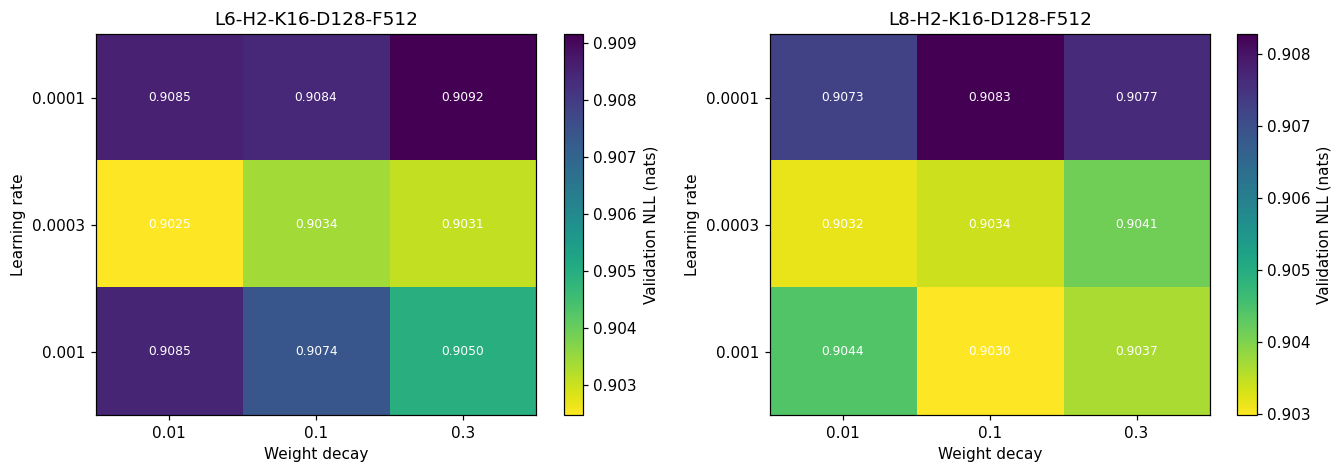

In [ ]:
fig, axes = plt.subplots(1, len(searched), figsize=(6.2 * len(searched), 4.4), squeeze=False)
for position, entry in enumerate(searched):
    ax = axes[0][position]
    subset = stage2_usable[stage2_usable["architecture"] == entry["architecture"]]
    grid = subset.pivot(index="learning_rate", columns="weight_decay", values="val_nll")
    image = ax.imshow(grid.to_numpy(), cmap="viridis_r", aspect="auto")
    ax.set_xticks(range(len(grid.columns)))
    ax.set_xticklabels([f"{value:g}" for value in grid.columns])
    ax.set_yticks(range(len(grid.index)))
    ax.set_yticklabels([f"{value:g}" for value in grid.index])
    ax.set_xlabel("Weight decay")
    ax.set_ylabel("Learning rate")
    ax.set_title(entry["architecture"])
    ax.grid(False)
    for row_number in range(len(grid.index)):
        for column_number in range(len(grid.columns)):
            value = grid.to_numpy()[row_number, column_number]
            if np.isfinite(value):
                ax.text(column_number, row_number, f"{value:.4f}", ha="center", va="center",
                        color="white", fontsize=8)
    fig.colorbar(image, ax=ax, label="Validation NLL (nats)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "09_stage2_lr_wd_grid.png", bbox_inches="tight")
plt.show()

**What are we looking at?** One heat map per searched architecture. Rows are learning rates, columns weight decays, and each cell holds the validation NLL of the single seed-0 run at that setting. Darker is lower. No run diverged (18 of 18 usable).

**What it shows.**

* **L6-H2-K16.** The three cells at learning rate 3e-4 are the lowest (0.9025–0.9034); both 1e-4 and 1e-3 are higher at every weight decay (0.9050–0.9092). The lowest cell is learning rate 3e-4, weight decay 0.01 (0.9025).
* **L8-H2-K16.** The picture is flatter: 3e-4 and 1e-3 give similar values (0.9030–0.9044), 1e-4 is higher (0.9073–0.9083). The lowest cell is learning rate 1e-3, weight decay 0.1 (0.9030).

**How to read it.** A minimum inside the grid means the range brackets the best setting; a minimum on an edge means the best setting may lie outside the range. Here the L6-H2 minimum is on the lower edge of the weight-decay range (0.01), and the L8-H2 minimum is on the upper edge of the learning-rate range (1e-3). The grid was not extended in either direction.

**What we cannot conclude.** Each cell is one seed. The three weight decays at learning rate 3e-4 for L6-H2 lie between 0.9025 and 0.9034, a spread smaller than the seed SDs of up to 0.0020 seen for these architectures in the capacity sweep. Stage 3 adds a second seed for this reason.

## 4. Stage 2 continued — warm-up fraction and batch size

The best learning rate and weight decay of each architecture are held fixed, and warm-up fraction and batch size are varied one at a time. The Track A values (warm-up 5%, batch 256) are already in the grid above and are not retrained.

In [ ]:
best_cells = {}
for entry in searched:
    subset = stage2_usable[stage2_usable["architecture"] == entry["architecture"]].sort_values("val_nll")
    best_cells[entry["architecture"]] = (float(subset.iloc[0]["learning_rate"]),
                                         float(subset.iloc[0]["weight_decay"]))
    print(f"{entry['architecture']}: best cell lr {best_cells[entry['architecture']][0]:g}, "
          f"wd {best_cells[entry['architecture']][1]:g} at val NLL {subset.iloc[0]['val_nll']:.4f}")

schedule_rows = []
for entry in searched:
    learning_rate, weight_decay = best_cells[entry["architecture"]]
    base = config_from_entry(entry, STAGE2_SEED, learning_rate=learning_rate, weight_decay=weight_decay)
    for warmup in WARMUP_FRACTIONS:
        if warmup == training.DEFAULT_TRAINING["warmup_fraction"]:
            continue
        run_dir, result = run_one(base, extra_training={"warmup_fraction": warmup}, verbose=False)
        schedule_rows.append(result_row(base, run_dir, result, group="stage2 warmup"))
        print(f"  {entry['architecture']} warm-up {warmup:g} -> val NLL {schedule_rows[-1]['val_nll']:.4f}")
    for batch_size in BATCH_SIZES:
        if batch_size == training.DEFAULT_TRAINING["batch_size"]:
            continue
        run_dir, result = run_one(base, extra_training={"batch_size": batch_size}, verbose=False)
        schedule_rows.append(result_row(base, run_dir, result, group="stage2 batch size"))
        print(f"  {entry['architecture']} batch {batch_size} -> val NLL {schedule_rows[-1]['val_nll']:.4f} "
              f"| {schedule_rows[-1]['runtime_seconds'] / 60:.1f} min")

search_table = append_results(schedule_rows, HYPERPARAMETER_RUNS_CSV)

L6-H2-K16-D128-F512: best cell lr 0.0003, wd 0.01 at val NLL 0.9025
L8-H2-K16-D128-F512: best cell lr 0.001, wd 0.1 at val NLL 0.9030
  L6-H2-K16-D128-F512 warm-up 0.02 -> val NLL 0.9039
  L6-H2-K16-D128-F512 warm-up 0.1 -> val NLL 0.9035
  L6-H2-K16-D128-F512 batch 128 -> val NLL 0.9001 | 3.2 min
  L6-H2-K16-D128-F512 batch 512 -> val NLL 0.9043 | 1.5 min
  L8-H2-K16-D128-F512 warm-up 0.02 -> val NLL 0.9038
  L8-H2-K16-D128-F512 warm-up 0.1 -> val NLL 0.9046
  L8-H2-K16-D128-F512 batch 128 -> val NLL 0.9015 | 4.1 min
  L8-H2-K16-D128-F512 batch 512 -> val NLL 0.9069 | 1.5 min


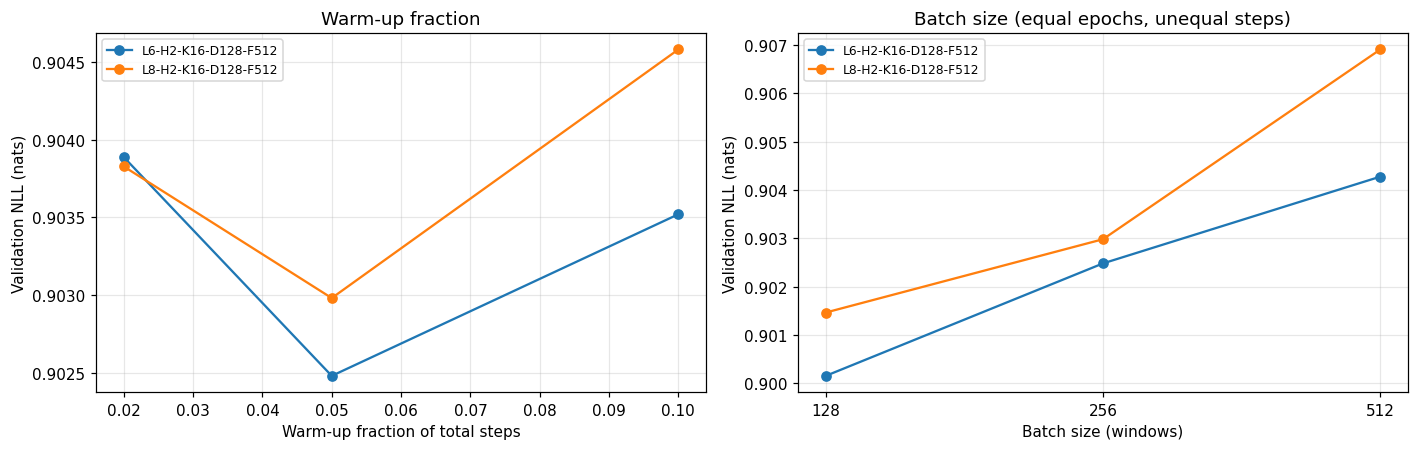

In [ ]:
stage2_all = search_table[search_table["group"].str.startswith("stage2")]
stage2_all.to_csv(STAGE2_SUMMARY_CSV, index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for entry in searched:
    learning_rate, weight_decay = best_cells[entry["architecture"]]
    at_best = stage2_all[(stage2_all["architecture"] == entry["architecture"])
                         & (stage2_all["learning_rate"] == learning_rate)
                         & (stage2_all["weight_decay"] == weight_decay)]
    warmup_points = at_best[at_best["batch_size"] == training.DEFAULT_TRAINING["batch_size"]].sort_values("warmup_fraction")
    batch_points = at_best[at_best["warmup_fraction"] == training.DEFAULT_TRAINING["warmup_fraction"]].sort_values("batch_size")
    axes[0].plot(warmup_points["warmup_fraction"], warmup_points["val_nll"], marker="o", label=entry["architecture"])
    axes[1].plot(batch_points["batch_size"], batch_points["val_nll"], marker="o", label=entry["architecture"])
axes[0].set_xlabel("Warm-up fraction of total steps")
axes[1].set_xlabel("Batch size (windows)")
axes[1].set_xscale("log", base=2)
axes[1].set_xticks(BATCH_SIZES)
axes[1].get_xaxis().set_major_formatter(plt.ScalarFormatter())
for ax, title in zip(axes, ["Warm-up fraction", "Batch size (equal epochs, unequal steps)"]):
    ax.set_ylabel("Validation NLL (nats)")
    ax.set_title(title)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "09_stage2_warmup_batch.png", bbox_inches="tight")
plt.show()

**What are we looking at?** Validation NLL against warm-up fraction (left) and against batch size (right), one line per architecture, at that architecture's best grid cell (L6-H2: learning rate 3e-4, weight decay 0.01; L8-H2: learning rate 1e-3, weight decay 0.1). Each point is one seed, so there are no error bars.

**RESULT.**

* **Warm-up.** The Track A value of 5% gives the lowest NLL for both architectures (L6-H2: 0.9025 against 0.9039 at 2% and 0.9035 at 10%; L8-H2: 0.9030 against 0.9038 and 0.9046).
* **Batch size.** NLL falls as the batch gets smaller for both architectures (L6-H2: 0.9001 at 128, 0.9025 at 256, 0.9043 at 512; L8-H2: 0.9015, 0.9030, 0.9069). Batch 128 took about twice as long as batch 512 (3.2 against 1.5 minutes for L6-H2).

**INTERPRETATION.** The warm-up comparison is like for like and gives no reason to change the Track A value. The batch-size comparison is not: with a fixed epoch budget, batch 128 performs twice as many optimiser steps per epoch as batch 256, so its lower NLL mixes the effect of batch size with the effect of more optimisation. It is reported as a sensitivity check, not used as a tuning axis.

**What we cannot conclude.** All points are single runs; the differences between warm-up values are of the same size as the seed spread observed in the capacity sweep.

## 5. Stage 3 — fine search around the best setting

The architecture and coarse cell with the lowest validation NLL in stage 2 is refined. The learning rates are the geometric midpoints between the selected value and the coarse grid points on either side (3e-4/√3 ≈ 1.73e-4 and 3e-4 × √3 ≈ 5.20e-4), plus the selected value itself. The weight decays are the selected value and its grid neighbours; because 0.01 is the lowest grid value, only one neighbour (0.1) exists. Two seeds per cell, so a cell is not promoted on one initialisation.

In [ ]:
stage2_best = stage2_all.sort_values("val_nll").iloc[0]
FINE_ARCHITECTURE = str(stage2_best["architecture"])
fine_entry = [entry for entry in SHORTLIST if entry["architecture"] == FINE_ARCHITECTURE][0]
centre_lr = float(stage2_best["learning_rate"])
centre_wd = float(stage2_best["weight_decay"])

fine_learning_rates = sorted({centre_lr, centre_lr / math.sqrt(3.0), centre_lr * math.sqrt(3.0)})
position = WEIGHT_DECAYS.index(centre_wd) if centre_wd in WEIGHT_DECAYS else 1
fine_weight_decays = sorted({WEIGHT_DECAYS[max(0, position - 1)], centre_wd,
                             WEIGHT_DECAYS[min(len(WEIGHT_DECAYS) - 1, position + 1)]})

print(f"Refining {FINE_ARCHITECTURE} around lr {centre_lr:g}, wd {centre_wd:g}")
print("Learning rates:", [f"{value:.3g}" for value in fine_learning_rates])
print("Weight decays:", fine_weight_decays)
print(f"Runs: {len(fine_learning_rates) * len(fine_weight_decays) * len(STAGE3_SEEDS)}")

Refining L6-H2-K16-D128-F512 around lr 0.0003, wd 0.01
Learning rates: ['0.000173', '0.0003', '0.00052']
Weight decays: [0.01, 0.1]
Runs: 12


In [ ]:
stage3_rows = []
for learning_rate in fine_learning_rates:
    for weight_decay in fine_weight_decays:
        for seed in STAGE3_SEEDS:
            config = config_from_entry(fine_entry, seed, learning_rate=learning_rate, weight_decay=weight_decay)
            run_dir, result = run_one(config, verbose=False)
            stage3_rows.append(result_row(config, run_dir, result, group="stage3 fine"))
        pair = [row for row in stage3_rows if row["learning_rate"] == learning_rate
                and row["weight_decay"] == weight_decay]
        print(f"  lr {learning_rate:<10.4g} wd {weight_decay:<6g} -> mean val NLL "
              f"{np.mean([row['val_nll'] for row in pair]):.4f} "
              f"(seeds {[round(row['val_nll'], 4) for row in pair]})")

search_table = append_results(stage3_rows, HYPERPARAMETER_RUNS_CSV)
stage3 = seed_level_to_config_level(search_table[search_table["group"] == "stage3 fine"])
stage3.to_csv(STAGE3_SUMMARY_CSV, index=False)
stage3[["architecture", "learning_rate", "weight_decay", "n_seeds", "val_nll", "val_nll_sd",
        "val_accuracy", "val_macro_f1", "val_top3", "val_top5", "val_ece", "best_epoch"]].round(4)

  lr 0.0001732  wd 0.01   -> mean val NLL 0.9036 (seeds [0.9055, 0.9018])
  lr 0.0001732  wd 0.1    -> mean val NLL 0.9033 (seeds [0.9052, 0.9015])
  lr 0.0003     wd 0.01   -> mean val NLL 0.9014 (seeds [0.9025, 0.9003])
  lr 0.0003     wd 0.1    -> mean val NLL 0.9020 (seeds [0.9034, 0.9006])
  lr 0.0005196  wd 0.01   -> mean val NLL 0.9042 (seeds [0.9056, 0.9028])
  lr 0.0005196  wd 0.1    -> mean val NLL 0.9044 (seeds [0.9058, 0.903])


,architecture,learning_rate,weight_decay,n_seeds,val_nll,val_nll_sd,val_accuracy,val_macro_f1,val_top3,val_top5,val_ece,best_epoch
0,L6-H2-K16-D128-F512,0.0003,0.01,2,0.9014,0.0016,0.6224,0.5565,0.9485,0.9944,0.0181,7.5
1,L6-H2-K16-D128-F512,0.0003,0.10,2,0.9020,0.0020,0.6230,0.5566,0.9487,0.9944,0.0209,7.5
2,L6-H2-K16-D128-F512,0.0002,0.10,2,0.9033,0.0026,0.6245,0.5609,0.9485,0.9939,0.0294,10.5
3,L6-H2-K16-D128-F512,0.0002,0.01,2,0.9036,0.0026,0.6242,0.5596,0.9486,0.9938,0.0289,10.5
4,L6-H2-K16-D128-F512,0.0005,0.01,2,0.9042,0.0020,0.6201,0.5572,0.9484,0.9942,0.0145,6.0
5,L6-H2-K16-D128-F512,0.0005,0.10,2,0.9044,0.0020,0.6198,0.5576,0.9484,0.9943,0.0139,6.0


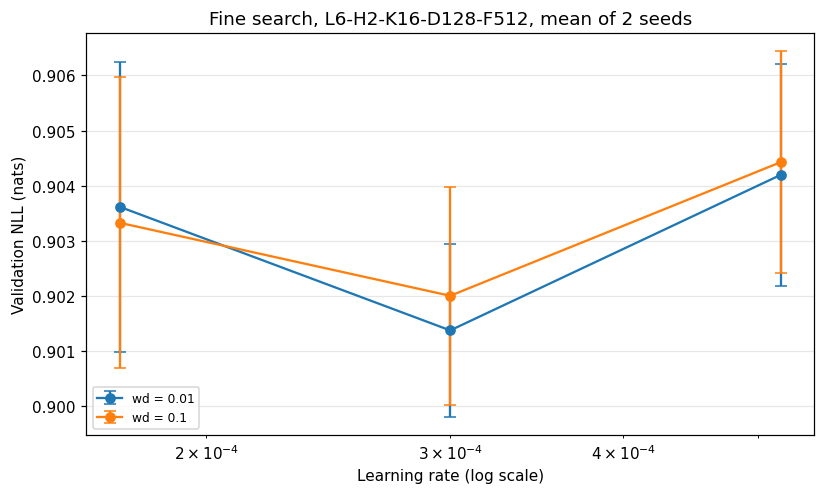

In [ ]:
fig, ax = plt.subplots(figsize=(7.6, 4.6))
for weight_decay in fine_weight_decays:
    line = stage3[stage3["weight_decay"] == weight_decay].sort_values("learning_rate")
    ax.errorbar(line["learning_rate"], line["val_nll"], yerr=line["val_nll_sd"].fillna(0),
                marker="o", capsize=4, label=f"wd = {weight_decay:g}")
ax.set_xscale("log")
ax.set_xlabel("Learning rate (log scale)")
ax.set_ylabel("Validation NLL (nats)")
ax.set_title(f"Fine search, {FINE_ARCHITECTURE}, mean of {len(STAGE3_SEEDS)} seeds")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "09_stage3_fine_search.png", bbox_inches="tight")
plt.show()

**What are we looking at?** Validation NLL against learning rate (log scale), one line per weight decay, for L6-H2-K16. Points are means over seeds 0 and 1; error bars are one standard deviation across those two seeds.

**RESULT.** Learning rate 3e-4 is the lowest point on both lines: 0.9014 at weight decay 0.01 (seeds 0.9025, 0.9003) and 0.9020 at weight decay 0.1 (seeds 0.9034, 0.9006). The midpoint learning rates are higher at both weight decays (1.73e-4: 0.9033–0.9036; 5.20e-4: 0.9042–0.9044).

**INTERPRETATION.** The refinement did not find a better learning rate than the coarse optimum of 3e-4, which is also the Track A value. At 3e-4, the gap between the two weight decays (0.9014 against 0.9020) is smaller than the seed SD of either cell (0.0016 and 0.0020). Whether that difference is more than noise is tested in the next section and again later with five seeds.

## 6. Comparison against the Track A training hyperparameters

**Question.** Does the best searched setting improve on the Track A setting for the same architecture?

**Decision rule ("better beyond noise").** Setting A is better than setting B beyond noise only if **both** hold:

1. **Data noise:** the 95% match-level bootstrap interval of the per-event NLL difference (A − B), computed on per-event validation NLL averaged over seeds, lies entirely below zero. Whole matches are resampled because events within a match are not independent.
2. **Training noise:** every seed of A has a lower validation NLL than every seed of B (complete seed separation).

This is the rule under which the Track A model was selected, so using it keeps the two experiments on the same footing; no threshold is chosen for this notebook.

**Control.** Same architecture (L6-H2-K16), same learning rate (3e-4), same seeds (0 and 1); only the weight decay differs (0.01 searched, 0.1 Track A). The Track A-setting runs are the ones already trained in the capacity sweep.

In [ ]:
fine_best = stage3.iloc[0]
fine_best_dirs = run_dirs_for(search_table[search_table["group"] == "stage3 fine"],
                              architecture=FINE_ARCHITECTURE,
                              learning_rate=fine_best["learning_rate"],
                              weight_decay=fine_best["weight_decay"])

track_a_setting_dirs = run_dirs_for(capacity_table, architecture=FINE_ARCHITECTURE,
                                    learning_rate=BASE_LR, weight_decay=BASE_WD)

if len(track_a_setting_dirs) == 0:
    print("The refined architecture was not trained at the Track A learning rate and weight decay "
          "in notebook 08; the comparison below is skipped.")
    hyperparameter_comparison = None
else:
    n_seeds = min(len(fine_best_dirs), len(track_a_setting_dirs))
    hyperparameter_comparison = analysis.compare_conditions(fine_best_dirs[:n_seeds],
                                                            track_a_setting_dirs[:n_seeds],
                                                            targets, match_ids)
    print(f"Architecture: {FINE_ARCHITECTURE}")
    print(f"Searched setting : lr {fine_best['learning_rate']:.4g}, wd {fine_best['weight_decay']:g}, "
          f"mean val NLL {hyperparameter_comparison['nll_a_mean']:.4f}")
    print(f"Track A setting  : lr {BASE_LR:g}, wd {BASE_WD:g}, "
          f"mean val NLL {hyperparameter_comparison['nll_b_mean']:.4f}")
    print(f"Difference (searched - Track A): {hyperparameter_comparison['difference_a_minus_b']:+.4f} nats "
          f"[{hyperparameter_comparison['difference_ci_low']:+.4f}, {hyperparameter_comparison['difference_ci_high']:+.4f}]")
    print(f"Seeds completely separated: {hyperparameter_comparison['seeds_completely_separated']}")
    print(f"Better beyond noise under the Track A rule: {hyperparameter_comparison['a_better_beyond_noise']}")

Architecture: L6-H2-K16-D128-F512
Searched setting : lr 0.0003, wd 0.01, mean val NLL 0.9014
Track A setting  : lr 0.0003, wd 0.1, mean val NLL 0.9020
Difference (searched - Track A): -0.0006 nats [-0.0013, +0.0001]
Seeds completely separated: False
Better beyond noise under the Track A rule: False


**RESULT.** Searched setting (weight decay 0.01): mean validation NLL 0.9014. Track A setting (weight decay 0.1): 0.9020. Difference −0.0006 nats, 95% match-level bootstrap interval [−0.0013, +0.0001]. The seeds are not completely separated. The searched setting is **not** better beyond noise.

**INTERPRETATION.** With two seeds per setting, the two weight decays cannot be distinguished: the interval includes zero and the seed results overlap. The point estimate favours 0.01, but the data are consistent with no difference.

**Why the searched setting is still carried forward.** The design of this experiment is to tune the training hyperparameters first and then benchmark every shortlisted architecture at the tuned setting. The tuned setting is defined as the fine-search cell with the lowest mean validation NLL, whether or not it passes the decision rule against the Track A setting. Because the evidence here rests on two seeds, the same comparison is repeated with five seeds in the benchmark (the "tuning check" candidate below).

## 7. Tuned training setting and the benchmark candidates

**Tuned training setting.** Learning rate and weight decay from the fine-search cell with the lowest mean validation NLL: learning rate 3e-4, weight decay 0.01. Batch size (256) and warm-up fraction (0.05) keep the Track A values: batch size was not compared at equal compute (Section 4), and warm-up was varied on one seed only, which does not support a change. Compared with Track A, only the weight decay changes (0.1 → 0.01).

**Candidates.**

1. **Benchmark** — every shortlisted architecture, including the Track A architecture (as 2L_2H_K16), trained at the tuned setting. Benchmark candidates differ in architecture only, so comparisons between them are architecture comparisons at one training setting. Only benchmark candidates are eligible for selection.
2. **Reference** — the frozen Track A configuration (2 layers, weight decay 0.1). It is the model the experiment is measured against and is not eligible for selection.
3. **Tuning check** — the fine-search architecture (L6-H2-K16) at the Track A hyperparameters (weight decay 0.1). Compared with the benchmark candidate of the same architecture, it repeats the comparison of Section 6 with five seeds. Not eligible for selection.

If the tuned setting had been identical to the Track A setting, the reference and tuning check would coincide with benchmark candidates and would not be added separately; that is not the case here.


In [ ]:
def configuration_label(entry):
    # Configuration name
    label = f"{entry['n_layers']}L_{entry['n_heads']}H_K{entry['context_length']}"
    if entry["d_model"] != BASE_D_MODEL or entry["d_ff"] != BASE_D_FF:
        label += f"_D{entry['d_model']}_F{entry['d_ff']}"
    return label


def candidate_record(name, architecture, learning_rate, weight_decay, source, role):
    entry = [item for item in SHORTLIST if item["architecture"] == architecture]
    if not entry:
        raise RuntimeError(f"{architecture} is not in the notebook 08 shortlist")
    entry = entry[0]
    return {"name": name, "label": configuration_label(entry), "role": role,
            "architecture": architecture, "n_layers": entry["n_layers"],
            "n_heads": entry["n_heads"], "context_length": entry["context_length"],
            "d_model": entry["d_model"], "d_ff": entry["d_ff"], "parameters": entry["parameters"],
            "learning_rate": float(learning_rate), "weight_decay": float(weight_decay),
            "batch_size": training.DEFAULT_TRAINING["batch_size"],
            "warmup_fraction": training.DEFAULT_TRAINING["warmup_fraction"],
            "is_track_a_reference": False, "source": source}


SELECTED_TRAINING = {"learning_rate": float(fine_best["learning_rate"]),
                     "weight_decay": float(fine_best["weight_decay"]),
                     "batch_size": training.DEFAULT_TRAINING["batch_size"],
                     "warmup_fraction": training.DEFAULT_TRAINING["warmup_fraction"],
                     "source": f"notebook 09 stage 3, lowest mean validation NLL over seeds {STAGE3_SEEDS}",
                     "tuned_on": [entry["architecture"] for entry in searched]}
tuned_equals_track_a = (SELECTED_TRAINING["learning_rate"] == BASE_LR
                        and SELECTED_TRAINING["weight_decay"] == BASE_WD)
track_a_architecture = architecture_label(transformer_config(0, BASE_LAYERS, BASE_HEADS, BASE_CONTEXT))

candidates = []
for entry in SHORTLIST:
    name = configuration_label(entry)
    is_reference = tuned_equals_track_a and entry["architecture"] == track_a_architecture
    if is_reference:
        name = "Track A reference"
    candidate = candidate_record(name, entry["architecture"], SELECTED_TRAINING["learning_rate"],
                                 SELECTED_TRAINING["weight_decay"],
                                 "notebook 08 shortlist, trained with the notebook 09 setting", "benchmark")
    candidate["is_track_a_reference"] = is_reference
    candidates.append(candidate)

if not tuned_equals_track_a:
    reference = candidate_record("Track A reference", track_a_architecture, BASE_LR, BASE_WD,
                                 "frozen Track A configuration", "reference")
    reference["is_track_a_reference"] = True
    candidates.append(reference)
    if FINE_ARCHITECTURE != track_a_architecture:
        check_label = configuration_label(fine_entry)
        candidates.append(candidate_record(f"{check_label} (Track A hyperparameters)", FINE_ARCHITECTURE,
                                           BASE_LR, BASE_WD,
                                           "tuning check: the fine-search architecture at the Track A "
                                           "training hyperparameters", "tuning check"))

names = [candidate["name"] for candidate in candidates]
assert len(names) == len(set(names)), "candidate names must be unique"
assert sum(candidate["is_track_a_reference"] for candidate in candidates) == 1

training.save_json(RESULTS_DIR / "09_selected_training.json", {
    "selected_training": SELECTED_TRAINING,
    "hyperparameter_comparison_vs_track_a": hyperparameter_comparison,
    "test_split_touched": False,
})
training.save_json(CANDIDATES_JSON, {
    "candidates": candidates,
    "selected_training": SELECTED_TRAINING,
    "stage2_grid": {"learning_rates": LEARNING_RATES, "weight_decays": WEIGHT_DECAYS,
                    "warmup_fractions": WARMUP_FRACTIONS, "batch_sizes": BATCH_SIZES,
                    "seed": STAGE2_SEED},
    "stage3_grid": {"architecture": FINE_ARCHITECTURE, "learning_rates": fine_learning_rates,
                    "weight_decays": fine_weight_decays, "seeds": STAGE3_SEEDS},
    "hyperparameter_comparison_vs_track_a": hyperparameter_comparison,
    "candidate_set_origin": ("every notebook 08 shortlisted architecture at the tuned setting (benchmark), "
                             "the frozen Track A configuration (reference) and the fine-search architecture "
                             "at the Track A hyperparameters (tuning check)"),
})
print("Tuned training setting:", json.dumps({key: SELECTED_TRAINING[key] for key in
                                              ["learning_rate", "weight_decay", "batch_size", "warmup_fraction"]}))
print(f"{len(candidates)} candidates written to {CANDIDATES_JSON}\n")
pd.DataFrame(candidates)[["name", "role", "architecture", "parameters", "learning_rate", "weight_decay",
                          "batch_size", "warmup_fraction", "source"]]

Tuned training setting: {"learning_rate": 0.0003, "weight_decay": 0.01, "batch_size": 256, "warmup_fraction": 0.05}
8 candidates written to /content/drive/MyDrive/soccer_mi/track_a/experiments/hyperparameter_optimisation/results/09_candidates.json



,name,role,architecture,parameters,learning_rate,weight_decay,batch_size,warmup_fraction,source
0,6L_2H_K16,benchmark,L6-H2-K16-D128-F512,1307663,0.0003,0.01,256,0.05,"notebook 08 shortlist, trained with the notebo..."
1,8L_2H_K16,benchmark,L8-H2-K16-D128-F512,1704207,0.0003,0.01,256,0.05,"notebook 08 shortlist, trained with the notebo..."
2,6L_1H_K16,benchmark,L6-H1-K16-D128-F512,1307663,0.0003,0.01,256,0.05,"notebook 08 shortlist, trained with the notebo..."
3,4L_2H_K16,benchmark,L4-H2-K16-D128-F512,911119,0.0003,0.01,256,0.05,"notebook 08 shortlist, trained with the notebo..."
4,6L_8H_K16,benchmark,L6-H8-K16-D128-F512,1307663,0.0003,0.01,256,0.05,"notebook 08 shortlist, trained with the notebo..."
5,2L_2H_K16,benchmark,L2-H2-K16-D128-F512,514575,0.0003,0.01,256,0.05,"notebook 08 shortlist, trained with the notebo..."
6,Track A reference,reference,L2-H2-K16-D128-F512,514575,0.0003,0.10,256,0.05,frozen Track A configuration
7,6L_2H_K16 (Track A hyperparameters),tuning check,L6-H2-K16-D128-F512,1307663,0.0003,0.10,256,0.05,tuning check: the fine-search architecture at ...


In [ ]:
search_table = pd.read_csv(HYPERPARAMETER_RUNS_CSV)
summary = {
    "runs_in_this_notebook": int(len(search_table)),
    "diverged_runs": int(search_table["diverged"].sum()),
    "gpu_hours": float(search_table["runtime_seconds"].sum() / 3600),
    "best_val_nll_in_search": float(search_table["val_nll"].min()),
    "best_setting": search_table.sort_values("val_nll").iloc[0][
        ["architecture", "learning_rate", "weight_decay", "batch_size", "warmup_fraction", "seed"]].to_dict(),
    "test_split_touched": False,
}
training.save_json(RESULTS_DIR / "09_summary.json", summary)
print(json.dumps(summary, indent=2, default=str))

{
  "runs_in_this_notebook": 36,
  "diverged_runs": 0,
  "gpu_hours": 1.5295613847838507,
  "best_val_nll_in_search": 0.9001492857933044,
  "best_setting": {
    "architecture": "L6-H2-K16-D128-F512",
    "learning_rate": 0.0003,
    "weight_decay": 0.01,
    "batch_size": 128,
    "warmup_fraction": 0.05,
    "seed": 0
  },
  "test_split_touched": false
}


## 8. Summary

| Item | Result |
|---|---|
| Runs recorded | 36; none diverged |
| Compute | 1.53 GPU-hours |
| Stage 2 best cell | L6-H2-K16: learning rate 3e-4, weight decay 0.01 (0.9025); L8-H2-K16: learning rate 1e-3, weight decay 0.1 (0.9030) — both on an edge of the grid |
| Warm-up | 5% (Track A value) lowest for both architectures |
| Batch size | 128 lowest (0.9001 for L6-H2, single seed), but not at equal compute; not adopted |
| Stage 3 best | L6-H2-K16, learning rate 3e-4, weight decay 0.01: 0.9014 (two seeds) |
| Searched vs Track A setting (L6-H2-K16, two seeds) | −0.0006 nats [−0.0013, +0.0001], seeds not separated: not better beyond noise |
| Tuned training setting | learning rate 3e-4, weight decay 0.01, batch 256, warm-up 0.05 |
| Candidates for the five-seed benchmark | 6 benchmark architectures, the Track A reference, and the tuning check (8 in total) |
| Test split | not accessed; no Track A file written |

Files produced: `results/09_hyperparameter_runs.csv` (one row per run), `results/09_selected_training.json` (the tuned setting and the comparison with Track A), `results/09_candidates.json` (the candidate list with roles).